# Quantum Metal 54 — two-qubit cell (D5–Z3) of the ETH 17-qubit surface-code mock-up, for meshing (Quantcore PDK rebuild)

**What the chip is.** Qiskit Metal `docs/circuit-examples/F.Small-quantum-chips/54-Wallraff_TwoQubit_Cell_Mesh.ipynb`,
which calls `wallraff_17q.build_cell(("D5", "Z3"))` from `resources/wallraff_17q/` (the builder of notebook 53,
traced from micrographs of Krinner *et al.*, Nature 605, 669 (2022); "a mockup, not a mask"), © Qiskit Metal
contributors, Apache-2.0 (<https://github.com/qiskit-community/qiskit-metal>); spec
`docs/designs/metal/54_wallraff_cell.md`; the id is prefixed `m` (ids do not start with a digit). We distribute the
rebuild under GPL-3.0. Data qubit `D5` and auxiliary qubit `Z3`, two `StarQubit` transmons (a centre island with
five pads at 72°: four couplers and a readout pad), joined by their lattice coupler line, cropped to the qubits plus a
350 µm margin. The source meshes it with gmsh and solves its capacitance matrix with ElmerFEM; that matrix is the
reference here.

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): the
Metal components are drawn through the `metal:<Class>` wrapper with the builder's own options; the chip, the stack,
the junctions, the route, the netlist and the LOM are ours.

| | Qiskit Metal 54 | Quantcore PDK rebuild |
|---|---|---|
| chip | a 2309.2 × 700 µm cut-out (qubits + 350 µm), centred on (804.6, 0) µm, D5 at the origin | the 7.5 × 7.5 mm Quantcore die with the QCT frame; the cut-out is centred in it (`box=(−2595.4, −3400, 4904.6, 4100)`), so every coordinate stays the source's (+350, +350) µm |
| substrate | silicon (the Elmer model) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| pads | none | none (nothing for the pad rule to move) |
| junctions | none (electrostatics only) | Quantcore Nb/AlOx/Nb trilayer junction in each StarQubit, PDK nominal 0.5 × 0.6 µm (R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF) |
| cheese | none (no GDS export; the source meshes the cut-out) | the PDK band (chip `cheese: "auto"`) |
| coupler | traced `PolylineCPW`, 8.5 / 5.5 µm, fillet 15 µm | a qcc `cpw` route on the same 31 points, same CPW and fillet |
| free pads | merged into `ground_plane` in the Elmer model | a snapped `metal:ShortToGround` on each (no geometry; it tells the LOM the pad is ground) |
| placement | as drawn | content centred in the die (already centred) |

**Kept exactly:** both `StarQubit`s with the builder's options (radius 160 µm, centre radius 53 µm, coupler /
readout gaps 13 / 6 µm, connector length 40 µm, 4 connectors) and pad rotations (D5: flux axis 0°, side +1; Z3:
side −1), the qubit positions (1609.2 µm apart) and the coupler line: the builder's traced `PolylineCPW` (31 points
after its simplification, 45 µm resampling and 40 µm pin leads) as waypoints, 8.5 / 5.5 µm CPW, fillet 15 µm.

The notebook goes step by step: PDK → die → (pads) → components → routes → centring → DRC → netlist → LOM →
FEM job → results back → one change re-simulated → fab export → snapshots → summary.

## 1 · Setup

The imports, the output folder and the `LIVE` switch: with KLayout open (the default), every step below is pushed to
the KLayout window as you run it; with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common`
holds the small helpers the design notebooks share (tables, snapshots, the PDK placement and fab helpers).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement and fab helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots
X0, Y0 = 350, 350                                # Metal's cell: D5 at the origin, chip = qubits + 350 µm margin
P = lambda x, y: (X0 + x, Y0 + y)                # Metal µm → Designer µm
STAR = dict(radius=160, center_radius=53, gap_couplers=13, gap_readout=6, connector_length=40, trap_offset=11,
            junc_h=53, number_of_connectors=4, resolution=16)
# pad rotations (Metal rotation_* = compass angle + 90), from wallraff_17q.pad_angles
ROT = {"D5": dict(rotation_cpl1=54, rotation_cpl2=198, rotation_cpl3=270, rotation_cpl4=342, rotation_rdout=126,
                  rotation_jj=90),
       "Z3": dict(rotation_cpl1=126, rotation_cpl2=198, rotation_cpl3=270, rotation_cpl4=342, rotation_rdout=54,
                  rotation_jj=90)}
# CPL_D5_Z3: the builder's PolylineCPW points (Metal µm, D5 at the origin), pin to pin
CPL = [(161.803, -117.557), (194.164, -141.068), (241.931, -158.748), (286.256, -154.887), (325.96, -132.643),
       (365.663, -110.4), (405.366, -88.157), (445.07, -65.914), (484.773, -43.67), (524.835, -22.131),
       (566.965, -5.701), (612.006, -0.019), (657.515, -0.101), (703.025, -0.183), (748.534, -0.265),
       (794.043, -0.347), (839.553, -0.429), (885.062, -0.511), (930.572, -0.593), (976.081, -0.675),
       (1021.591, -0.757), (1067.1, -0.839), (1111.078, -6.611), (1146.044, -33.885), (1173.559, -68.899),
       (1212.674, -79.346), (1248.118, -52.991), (1277.88, -19.456), (1318.218, -2.612), (1369.2, 0.0),
       (1409.2, 0.0)]
ELMER = {"D5": 167.02, "Z3": 168.07, "D5-cpl": 18.39, "Z3-cpl": 18.40, "D5-Z3": 0.06}  # source's Elmer C (fF)

## 2 · The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that means: the 7.5 mm die gets the QCT frame round the small cut-out; there are no pads for the pad rule; both StarQubits get the PDK nominal trilayer junction; the free ground gets the PDK cheese band.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## 3 · The die and its frame

`Designer(name, box=...)` opens an empty chip. The box is the die (µm); the PDK draws the **QCT frame** on it: L
dicing markers in the four corners (1000/0), a 3 × 3 alignment grid in each corner area (1001/0), the chip boundary
(100/0) and the device ID `name_chip` on a free edge (optional: no free edge, no ID). The source's cut-out spans
(0, 0)–(2309.2, 700) µm here (`P(x, y)` = Metal + (350, 350)); the 7.5 mm die is centred on it.

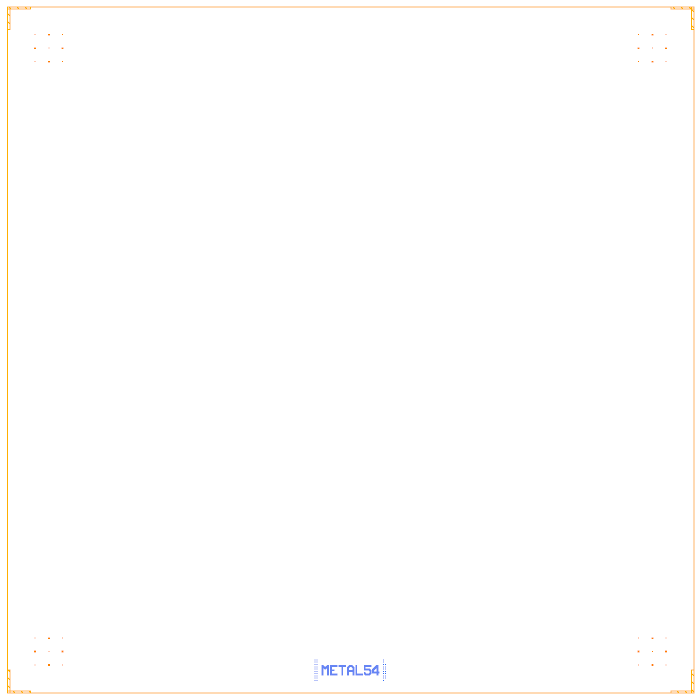

WindowsPath('examples/designs/metal/m54_wallraff_cell_step_die.png')

In [4]:
d = Designer("m54_wallraff_cell", box=(-2595.4, -3400, 4904.6, 4100), chip={"name_chip": "Metal54"}, live=LIVE)
rebuild(d)                                       # build the empty die (a no-op when LIVE: it is already built)
snap(d, OUT / "m54_wallraff_cell_step_die.png", size=(700, 700), width=350)

## 4 · Pads

The source is a meshing cut-out of two qubits and their coupler: no launchpads, readouts or control lines, so the
PDK pad rule (outer etch edge 100 µm from the die edge) has nothing to place; `pads_md(d)` in step 7 confirms there
are none.

## 5 · Components: the two StarQubits and their grounded pads

**The qubits.** `metal:StarQubit` is Metal's star transmon: a centre island (radius 53 µm) with the junction, and
five pads at 72° — four coupler pads `pin_cpl1`–`pin_cpl4` and a readout pad `pin_rdout` — each in its own gap
(13 / 6 µm). The rotations set where each pad points (the builder's `pad_angles`): D5's `pin_cpl1` faces Z3, Z3's
`pin_cpl3` faces D5.

**The junction.** With `junction_type` unset the wrapper already draws the Quantcore trilayer junction;
`trilayer_junction` makes it explicit and returns the drawn junction's L_J and C_J for the LOM and the FEM junction
port (`junction=`). The source has no junctions (it is an electrostatics study), so both qubits get the PDK nominal
junction (fingers 0.5 × 0.6 µm on 2/0 + 4/0, a 50/0 spacer with the 51–53/0 dose gradient, R_n 45 kΩ, L_J 6.73 nH,
C_J 15 fF).

**The free pads.** The pads without a line (D5: `cpl2`, `cpl3`, `cpl4`, readout; Z3: `cpl1`, `cpl2`, `cpl4`,
readout) end at the pocket edge, so in this cut-out they are ground, as in the source's Elmer model (which merges them
into `ground_plane`). Each gets a `metal:ShortToGround` snapped to its pin (`snap="short", to=<pin>`): no geometry,
it tells the LOM the pad is grounded.

junction: {'junction_type': 'Quantcore Junction'} {'Lj_nH': 6.7344, 'Cj_fF': 15.0}


D5 ports: ['pin_cpl1', 'pin_cpl2', 'pin_cpl3', 'pin_cpl4', 'pin_rdout', 'squid_a', 'squid_b']


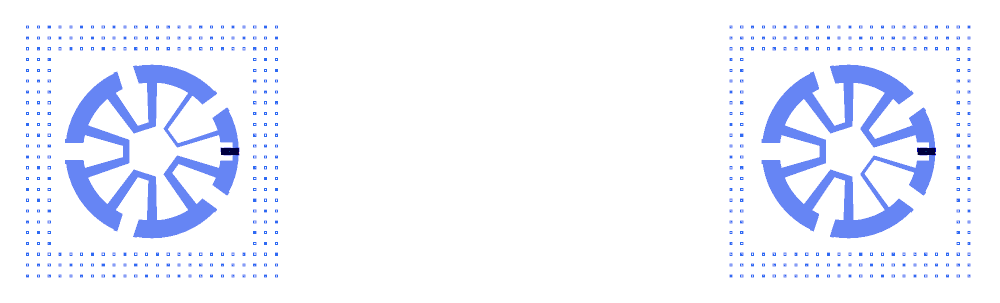

WindowsPath('examples/designs/metal/m54_wallraff_cell_step_parts.png')

In [5]:
# Quantcore trilayer junction on the PDK rule (Nb Δ 1.4 meV): nominal fingers 0.5 × 0.6 µm → R_n 45 kΩ,
# L_J 6.73 nH, C_J 15 fF. JJ_PARAMS = {"junction_type": "Quantcore Junction"}; JUNCTION = its {Lj_nH, Cj_fF}
JJ_PARAMS, JUNCTION = trilayer_junction("metal:TransmonPocket")
print("junction:", JJ_PARAMS, JUNCTION)
with d.batch():
    q = {n: d.add(n, "metal:StarQubit", at=P(x, 0), junction=JUNCTION, **JJ_PARAMS, **STAR, **ROT[n])
         for n, x in (("D5", 0), ("Z3", 1609.2))}
    # the free pads end at the pocket edge: ground in this cut-out (the source's Elmer model)
    for n, pins in (("D5", ("pin_cpl2", "pin_cpl3", "pin_cpl4", "pin_rdout")),
                    ("Z3", ("pin_cpl1", "pin_cpl2", "pin_cpl4", "pin_rdout"))):
        for pin in pins:
            d.add(f"{n}_{pin}_gnd", "metal:ShortToGround", snap="short", to=getattr(q[n], pin))
print("D5 ports:", sorted(q["D5"].ports))
snap(d, OUT / "m54_wallraff_cell_step_parts.png", box=(0, 0, 2309.2, 700), size=(1000, 303), width=500)

## 6 · Routes: the coupler line

`CPL_D5_Z3` runs from D5's `pin_cpl1` to Z3's `pin_cpl3` through the builder's traced points (the first and last are
the pins themselves, so the interior 29 are the waypoints), on the source's 8.5 / 5.5 µm CPW with its 15 µm fillet.
The route is 1349.7 µm long (the builder's polyline, 1351.7 µm, less what the 15 µm fillets cut off).

**Sim group:** `cell` — both qubits and the coupler, with the box at the cut-out's own extent (margin 0, as in the
source's mesh), for a Q3D C-matrix job.

route lengths (µm): {'CPL_D5_Z3': 1349.7}


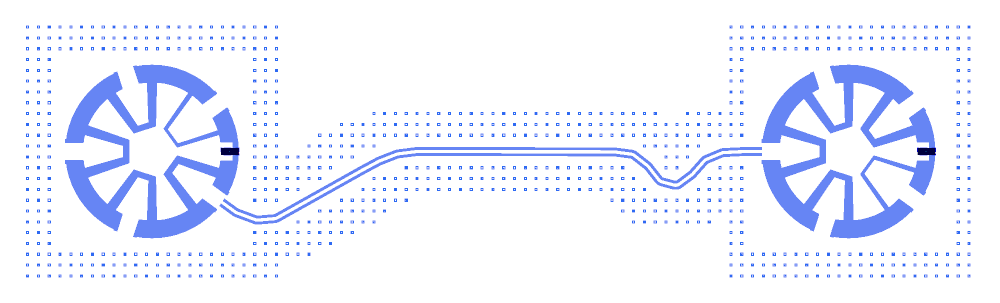

WindowsPath('examples/designs/metal/m54_wallraff_cell_step_routes.png')

In [6]:
with d.batch():
    d.route("CPL_D5_Z3", q["D5"].pin_cpl1, q["Z3"].pin_cpl3, a=8.5, b=5.5, r=15, nodes=[P(*p) for p in CPL[1:-1]])
d.sim_group("cell", ["D5", "Z3", "CPL_D5_Z3"], margin_um=0, analyses=["q3d_cmatrix"])
rebuild(d)
print("route lengths (µm):", {k: round(v, 1) for k, v in d.result.route_lengths().items()})
snap(d, OUT / "m54_wallraff_cell_step_routes.png", box=(0, 0, 2309.2, 700), size=(1000, 303), width=500)

## 7 · Centre the content and save

The PDK wants the chip content centred in the die. `center_in_die` measures the bounding box of everything placed
(components and routes: here the two stars, radius 160 µm plus their 40 µm connectors, so (150, 150)–(2159.2, 550)
µm) and shifts the design so its centre is the die centre. The die was centred on the cut-out, so nothing moves.
Then the design is saved: the JSON is the deliverable.

In [7]:
shift = center_in_die(d)
rebuild(d)
box = content_box(d)
print("content shifted by", shift, "µm; content box", (round(box.left, 1), round(box.bottom, 1), round(box.right, 1),
      round(box.top, 1)))
display(Markdown(pads_md(d)))
DESIGN = d.save(OUT / "m54_wallraff_cell.json")
print(d, "→", DESIGN)

content shifted by (0.0, 0.0) µm; content box (150.0, 150.0, 2159.2, 550.0)


| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| – | no bond pads or launchers | – | – | – |

<Designer m54_wallraff_cell: 10 instances, 1 routes, live=False> → examples\designs\metal\m54_wallraff_cell.json


## 8 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here: **no errors**, four `dangling_port` warnings (`D5` / `Z3` `squid_a` / `squid_b`, the
junction's attachment points: the StarQubit cell draws the junction itself, nothing is routed there) and **no PDK
design warnings** (no pads, the nominal junction is in the R_n window, no targets).

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [8]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

**0 errors · 4 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 4 | D5.squid_a is not connected (no route or snap) |

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (-0, +0) µm |
| junction types | Quantcore Junction × 2 |
| PDK design warnings | 0 (none) |

## 9 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit: each `StarQubit` gives a grounded centre island with its junction
and a node per pad (C to the island and to ground); the two coupler pads joined by `CPL_D5_Z3` are one node (the
coupler, a 1.35 mm open–open line, far above the qubits); the free pads are ground through their `ShortToGround`s.
The port map shows where each of D5's ports landed.

In [9]:
lb = d.lom()
show_netlist(lb)
print({k: v for k, v in lb.port_map.items() if k.startswith("D5.")})

**12 nodes · 24 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `D5` | `D5.island` |
| `D5.pin_cpl1` | `D5.pin_cpl1`, `Z3.pin_cpl3` |
| `D5.pin_cpl2` | `D5.pin_cpl2`, `D5_pin_cpl2_gnd.end` |
| `D5.pin_cpl3` | `D5.pin_cpl3`, `D5_pin_cpl3_gnd.end` |
| `D5.pin_cpl4` | `D5.pin_cpl4`, `D5_pin_cpl4_gnd.end` |
| `D5.pin_rdout` | `D5.pin_rdout`, `D5_pin_rdout_gnd.end` |
| `Z3` | `Z3.island` |
| `Z3.pin_cpl1` | `Z3.pin_cpl1`, `Z3_pin_cpl1_gnd.end` |
| `Z3.pin_cpl2` | `Z3.pin_cpl2`, `Z3_pin_cpl2_gnd.end` |
| `Z3.pin_cpl4` | `Z3.pin_cpl4`, `Z3_pin_cpl4_gnd.end` |
| `Z3.pin_rdout` | `Z3.pin_rdout`, `Z3_pin_rdout_gnd.end` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `C_D5` | C | `D5` – `gnd` | 26 fF |
| `J_D5` | JJ | `D5` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_D5_pin_cpl1` | C | `D5` – `D5.pin_cpl1` | 15 fF |
| `Cc_D5_pin_cpl1` | C | `D5.pin_cpl1` – `gnd` | 13 fF |
| `Cg_D5_pin_cpl2` | C | `D5` – `D5.pin_cpl2` | 15 fF |
| `Cc_D5_pin_cpl2` | C | `D5.pin_cpl2` – `gnd` | 13 fF |
| `Cg_D5_pin_cpl3` | C | `D5` – `D5.pin_cpl3` | 15 fF |
| `Cc_D5_pin_cpl3` | C | `D5.pin_cpl3` – `gnd` | 13 fF |
| `Cg_D5_pin_cpl4` | C | `D5` – `D5.pin_cpl4` | 15 fF |
| `Cc_D5_pin_cpl4` | C | `D5.pin_cpl4` – `gnd` | 13 fF |
| `Cg_D5_pin_rdout` | C | `D5` – `D5.pin_rdout` | 18 fF |
| `Cc_D5_pin_rdout` | C | `D5.pin_rdout` – `gnd` | 16 fF |
| `C_Z3` | C | `Z3` – `gnd` | 26 fF |
| `J_Z3` | JJ | `Z3` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Z3_pin_cpl1` | C | `Z3` – `Z3.pin_cpl1` | 15 fF |
| `Cc_Z3_pin_cpl1` | C | `Z3.pin_cpl1` – `gnd` | 13 fF |
| `Cg_Z3_pin_cpl2` | C | `Z3` – `Z3.pin_cpl2` | 15 fF |
| `Cc_Z3_pin_cpl2` | C | `Z3.pin_cpl2` – `gnd` | 13 fF |
| `Cg_Z3_pin_cpl3` | C | `Z3` – `D5.pin_cpl1` | 15 fF |
| `Cc_Z3_pin_cpl3` | C | `D5.pin_cpl1` – `gnd` | 13 fF |
| `Cg_Z3_pin_cpl4` | C | `Z3` – `Z3.pin_cpl4` | 15 fF |
| `Cc_Z3_pin_cpl4` | C | `Z3.pin_cpl4` – `gnd` | 13 fF |
| `Cg_Z3_pin_rdout` | C | `Z3` – `Z3.pin_rdout` | 18 fF |
| `Cc_Z3_pin_rdout` | C | `Z3.pin_rdout` – `gnd` | 16 fF |

**Unconnected ports:** none

{'D5.squid_a': 'D5', 'D5.squid_b': 'gnd', 'D5.pin_cpl1': 'D5.pin_cpl1', 'D5.pin_cpl2': 'D5.pin_cpl2', 'D5.pin_cpl3': 'D5.pin_cpl3', 'D5.pin_cpl4': 'D5.pin_cpl4', 'D5.pin_rdout': 'D5.pin_rdout'}


## 10 · LOM simulation and the source's Elmer capacitances

The capacitances the LOM estimates against the source's ElmerFEM matrix, then the two qubits with the coupler, once
from the LOM estimates and once from the source's Elmer matrix (free pads in ground, the PDK junctions).

- The StarQubit model is rough: its C_Σ is well below Elmer's 167 fF (the star arms are neglected), and C(island,
  coupler) a little below Elmer's 18.4 fF.
- **The LOM coupler is too light:** a `cpw` route between two pads is a wire, so the coupler node has only the two
  pads' capacitance to ground instead of Elmer's 382 fF (the 1.35 mm line alone is ≈ 195 fF). Reported; the LOM mode splitting is therefore not a result.
- From the Elmer matrix (C_Σ 167 / 168 fF, E_C ≈ 116 MHz) with the PDK 6.73 nH both qubits sit near 4.6 GHz; they are
  nearly degenerate, so the two modes are mixed and a per-pair ZZ is not defined.

In [10]:
def c_sum(model, node, other=None):
    """Sum of the C branch estimates between ``node`` and ``other`` (any node if None), fF."""
    tot = 0.0
    for b in model.branches.values():
        if b.type == "C" and node in b.nodes and (other is None or other in b.nodes):
            tot += b.value["estimate"]
    return tot

cpl = next(n for n in lb.model.nodes if n.startswith("D5.pin_cpl1"))   # the coupler net
rows = ["| quantity | LOM estimate (fF) | Elmer, source (fF) |", "|---|---|---|"]
for n in ("D5", "Z3"):
    rows.append(f"| C_Σ {n} | {c_sum(lb.model, n):.1f} | {ELMER[n]} |")
    rows.append(f"| C({n}, coupler) | {c_sum(lb.model, n, cpl):.2f} | {ELMER[n + '-cpl']} |")
display(Markdown("\n".join(rows)))
res = simulate_groups(d, {"cell": ["D5", "Z3", "CPL_D5_Z3"]}, max_modes=3)
display(Markdown("**D5–coupler–Z3 from the LOM estimates, QuCat normal modes:**\n\n" + modes_md(res["cell"])))

# the same circuit from the source's Elmer C-matrix (free pads in ground), with the PDK junctions
from quantcore_circuits.circuit.fill import fill
from quantcore_circuits.circuit.schema import CircuitModel
C = lambda a, b, v: {"type": "C", "nodes": [a, b], "value": {"estimate": v}}
JJ = lambda n: {"type": "JJ", "nodes": [n, "gnd"], "value": dict(JUNCTION)}
elmer_model = CircuitModel.model_validate({"name": "m54_elmer", "nodes": {"gnd": {"ground": True}, "D5": {}, "Z3": {}, "cpl": {}},
    "branches": {"C_D5": C("D5", "gnd", ELMER["D5"] - ELMER["D5-cpl"] - ELMER["D5-Z3"]),
                 "C_Z3": C("Z3", "gnd", ELMER["Z3"] - ELMER["Z3-cpl"] - ELMER["D5-Z3"]),
                 "C_cpl": C("cpl", "gnd", 381.59), "Cg_D5": C("D5", "cpl", ELMER["D5-cpl"]),
                 "Cg_Z3": C("Z3", "cpl", ELMER["Z3-cpl"]), "C_D5_Z3": C("D5", "Z3", ELMER["D5-Z3"]),
                 "J_D5": JJ("D5"), "J_Z3": JJ("Z3")}})
res_elmer = {"cell (Elmer C)": simulate(fill(elmer_model, None), max_modes=2)}
display(Markdown("**D5–coupler–Z3 from the source's Elmer C-matrix, QuCat normal modes:**\n\n" + modes_md(res_elmer["cell (Elmer C)"])))
display(Markdown("**Static ZZ (QuTiP):**\n\n" + zz_md(res | res_elmer)))

| quantity | LOM estimate (fF) | Elmer, source (fF) |
|---|---|---|
| C_Σ D5 | 104.0 | 167.02 |
| C(D5, coupler) | 15.00 | 18.39 |
| C_Σ Z3 | 104.0 | 168.07 |
| C(Z3, coupler) | 15.00 | 18.4 |

**D5–coupler–Z3 from the LOM estimates, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| D5 | qubit | 6.6380 | 0 | 113.5 | J_Z3 0.50, J_D5 0.50 |
| Z3 | qubit | 6.9743 | 0 | 125.2 | J_D5 0.50, J_Z3 0.50 |

**D5–coupler–Z3 from the source's Elmer C-matrix, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Z3 | qubit | 4.5367 | 0 | 67.2 | J_Z3 0.76, J_D5 0.24 |
| D5 | qubit | 4.5621 | 0 | 67.9 | J_D5 0.76, J_Z3 0.24 |

**Static ZZ (QuTiP):**

| group | pair | ZZ (kHz) | neighbours | hybridised |
|---|---|---|---|---|
| cell | D5-Z3 | – | yes | yes |
| cell (Elmer C) | D5-Z3 | – | yes | yes |

## 11 · FEM: send the job

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for.

One Q3D C-matrix job for the group `cell`, with the box at the chip's own extent (margin 0, as in the source's
mesh). Its nets are the LOM's nodes, so after a solve it gives the matrix the source got from Elmer. In this run the
exporter names both islands (`D5.island`, `Z3.island`) but still prints "Unable to create polygon for port 1 / 2"
for the StarQubit junction ports, and the coupler line is a waveguide port pair, not a named net (an exporter limit
for this cell, reported before the rebuild).

`RUN_FEM = False` keeps the notebook fast. Set it to `True` to solve the jobs here: `send_fem_jobs` finds AEDT 2024
R1 (or newer) and solves each Ansys job in a **new batch, non-graphical** AEDT, so an AEDT window you have open is
never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [11]:
jobs = export_sims(DESIGN)
display(Markdown(jobs_md(jobs)))

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| cell | `build/jobs/m54_wallraff_cell_cell_q3d_cmatrix` | 1 · junction · `D5.junction`<br>2 · junction · `Z3.junction`<br>3 · waveguide · `D5.pin_cpl1`<br>4 · waveguide · `Z3.pin_cpl3` | `D5.island`, `Z3.island` |

In [12]:
RUN_FEM = False   # True: solve the jobs now in a new batch AEDT (2024 R1 or newer)
if RUN_FEM:
    send_fem_jobs(DESIGN, ['cell'], run=True)

## 12 · Bring the FEM results back

When a job has been solved, its folder holds `results/results.json`. `fem_back` fills the LOM with the extracted
C-matrix (matched by net name: the job's nets are the LOM's nodes) and lists each capacitance as estimate vs
extracted. Without results it says what would appear; the LOM values above stay the estimates.

In [13]:
filled, back_md = fem_back(lb.model, DESIGN, {f"{g} · q3d": v for g, v in jobs.items()})
display(Markdown(back_md))
for key, fc in filled.items():                   # re-simulate the LOM on the extracted values
    display(Markdown(f"**{key}, LOM on the FEM values:**"))
    display(Markdown(modes_md(simulate(fc))))

No FEM results yet for cell · q3d: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 13 · Iterate: change one property and re-simulate

A design loop in one cell: copy the saved design (`design_copy`: a non-live Designer that never writes over the
JSON), change one property — here D5's centre island, `center_radius` 53 → 70 µm (the pins stay where they are, so the
coupler line still fits) — rebuild, re-run the LOM of the cell and compare. A bigger island adds to D5's C_Σ: D5 moves
down and away from Z3, so the two qubits un-mix.

In [14]:
d2 = design_copy(DESIGN)
d2["D5"].set(center_radius=70)                   # 53 → 70 µm
after = simulate_groups(d2, {"cell": ["D5", "Z3", "CPL_D5_Z3"]}, max_modes=3)
display(Markdown(params_delta_md(res, after)))

| parameter | before | after | Δ |
|---|---|---|---|
| `cell: D5.f_q_GHz` | 6.3963 | 5.9831 | -0.4132 |
| `cell: D5.alpha_MHz` | -149.95 | -193.41 | -43.46 |
| `cell: Z3.f_q_GHz` | 6.7204 | 6.5955 | -0.1249 |
| `cell: Z3.alpha_MHz` | -111.33 | -215.3 | -104 |

## 14 · Build and export

The design JSON saved in step 7 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese.** Notebook 54 never exports a GDS (it meshes the cut-out with gmsh), so the original has no
cheese: the PDK band applies (`cheese: "auto"`, the default). The build draws it into KQC's `ground_grid` layer
(5 µm squares, 20 µm gaps, three rows round the 3/0 keep-outs) and `export_fab` keeps it (`cheese source: build`).

Command-line equivalents:
- `qcc build examples/designs/metal/<id>.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/<id>.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/<id>.json -g <group> -a q3d_cmatrix` (one FEM job).

In [15]:
print("design file:", DESIGN)
CHEESE = True
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

design file: examples\designs\metal\m54_wallraff_cell.json


| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 786 |
| 2/0 | JJ_STRAIGHT | 2 |
| 3/0 | M3 | 777 |
| 4/0 | JJ_BENT | 2 |
| 50/0 | HSQ | 4 |
| 51/0 | SPACER_1 | 4 |
| 52/0 | SPACER_2 | 4 |
| 53/0 | SPACER_3 | 4 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 775 holes on the mask.

→ `build/m54_wallraff_cell_fab.oas`

## 15 · Snapshots

The full die; the cell (compare the source's `qm.view` figure); D5 with its five pads and the coupler leaving at
324°; Z3; D5's trilayer junction; the **fab mask** round D5 (1/0 etch with the PDK cheese band, the 3/0 keep-out, the
junction layers); and the die frame's south-west corner (dicing L on 1000/0, alignment grid on 1001/0). Positions are
read from the design.

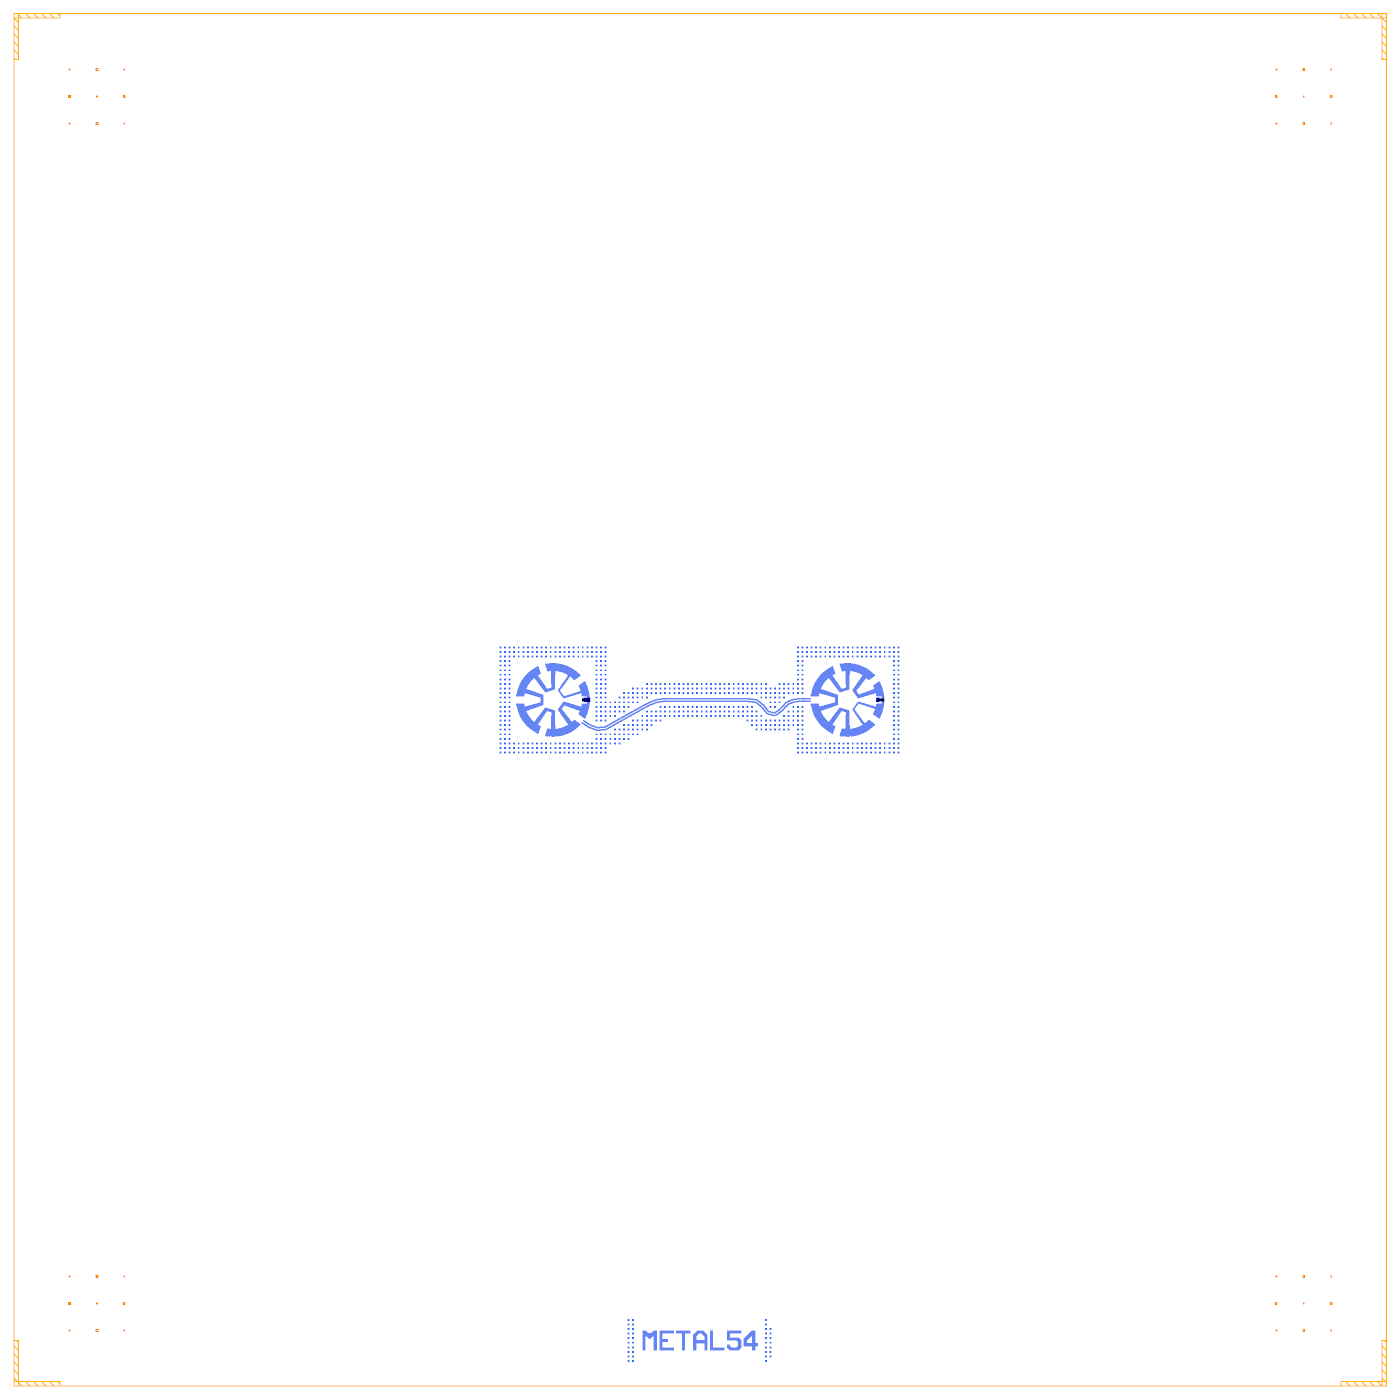

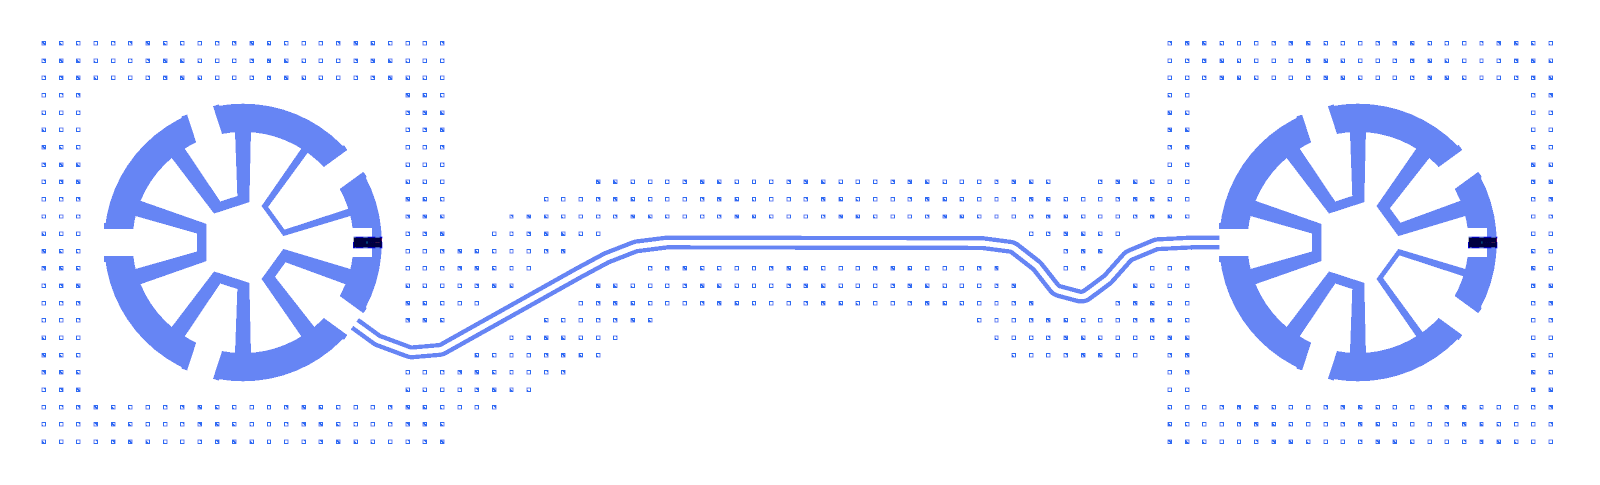

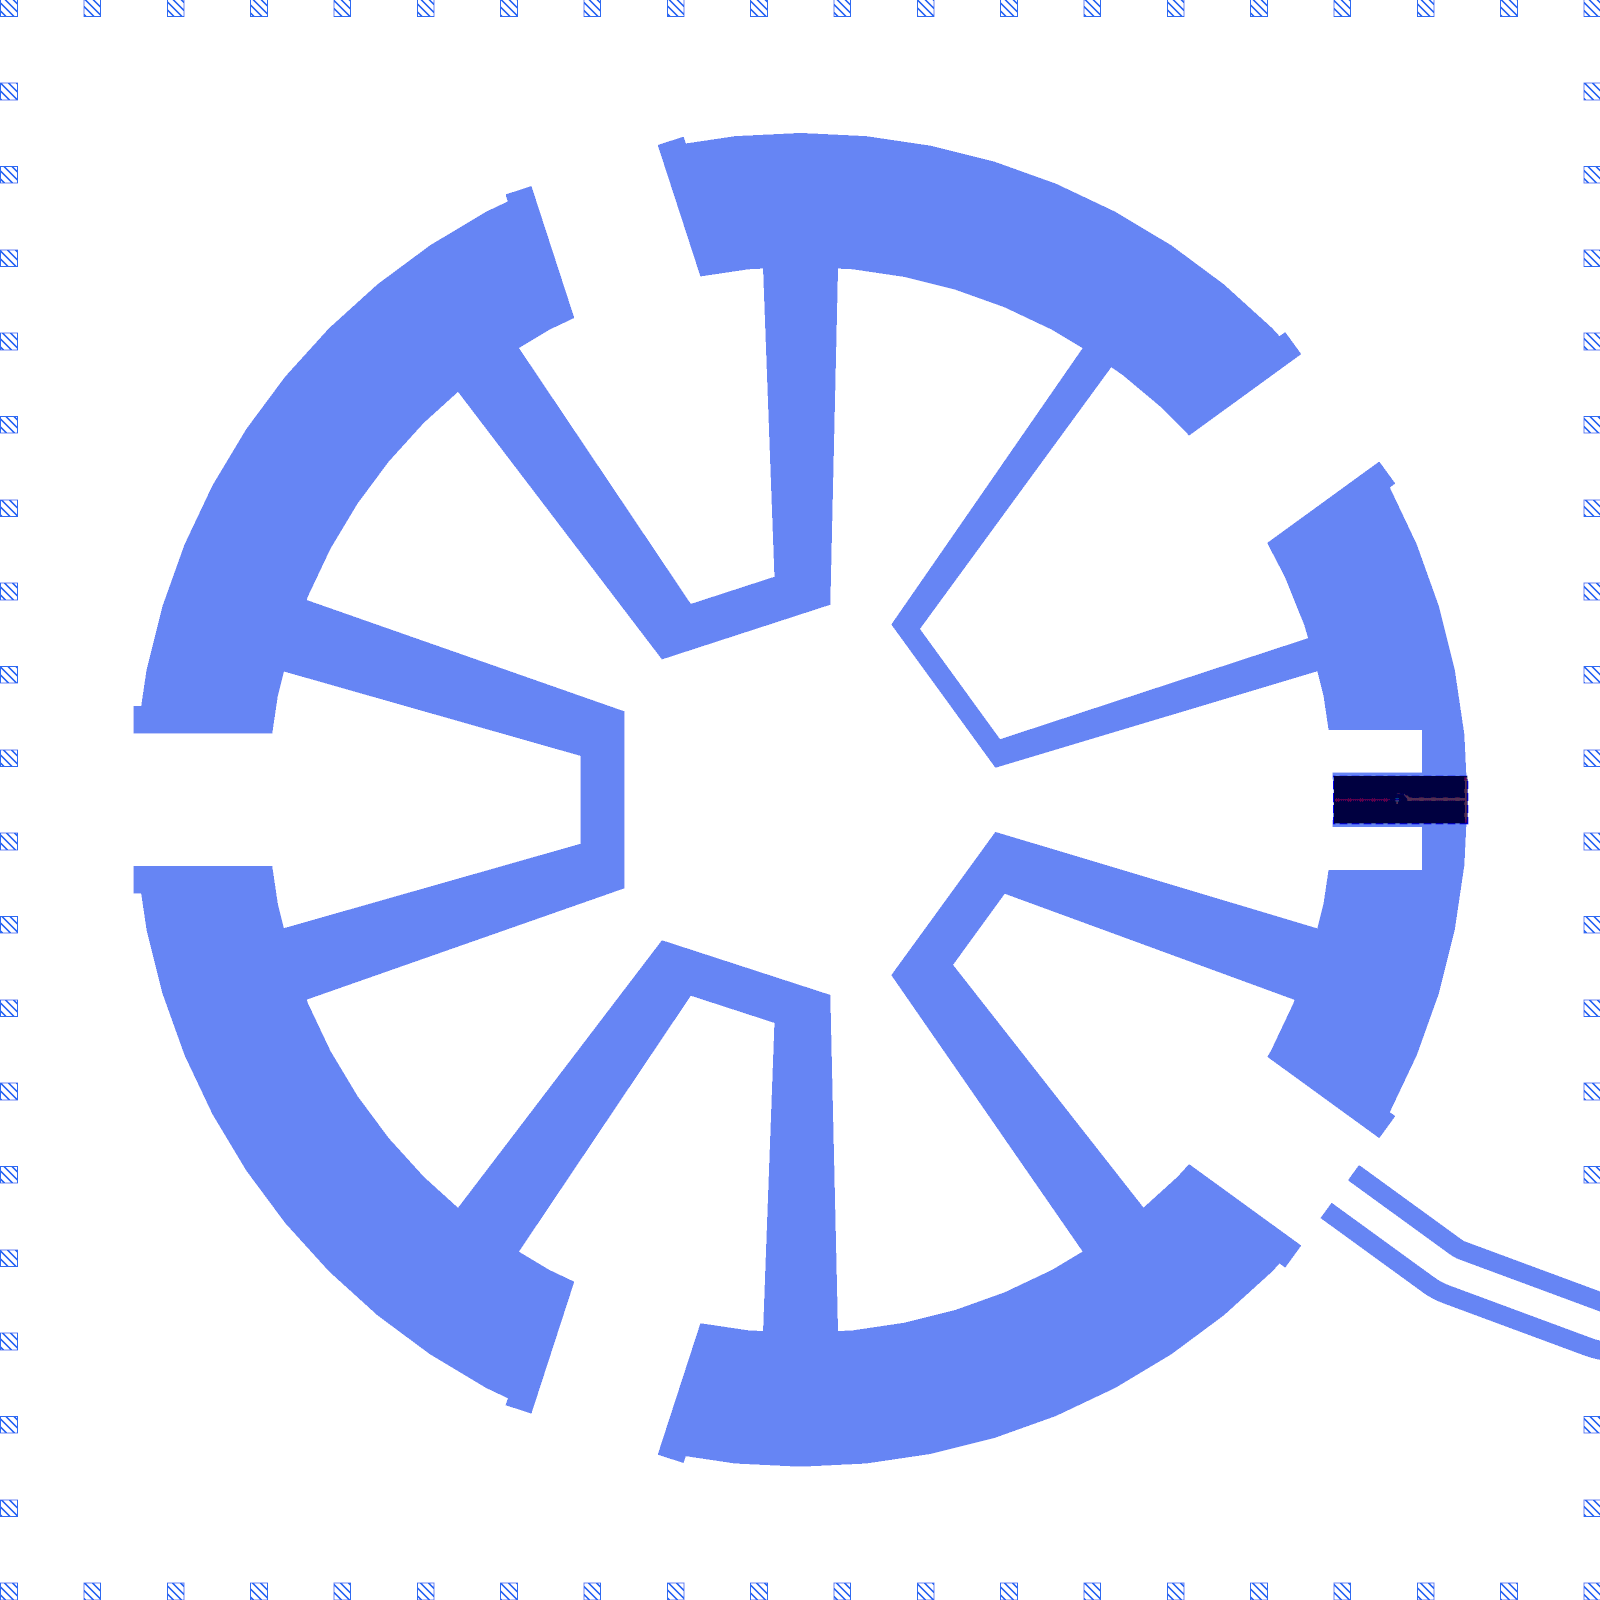

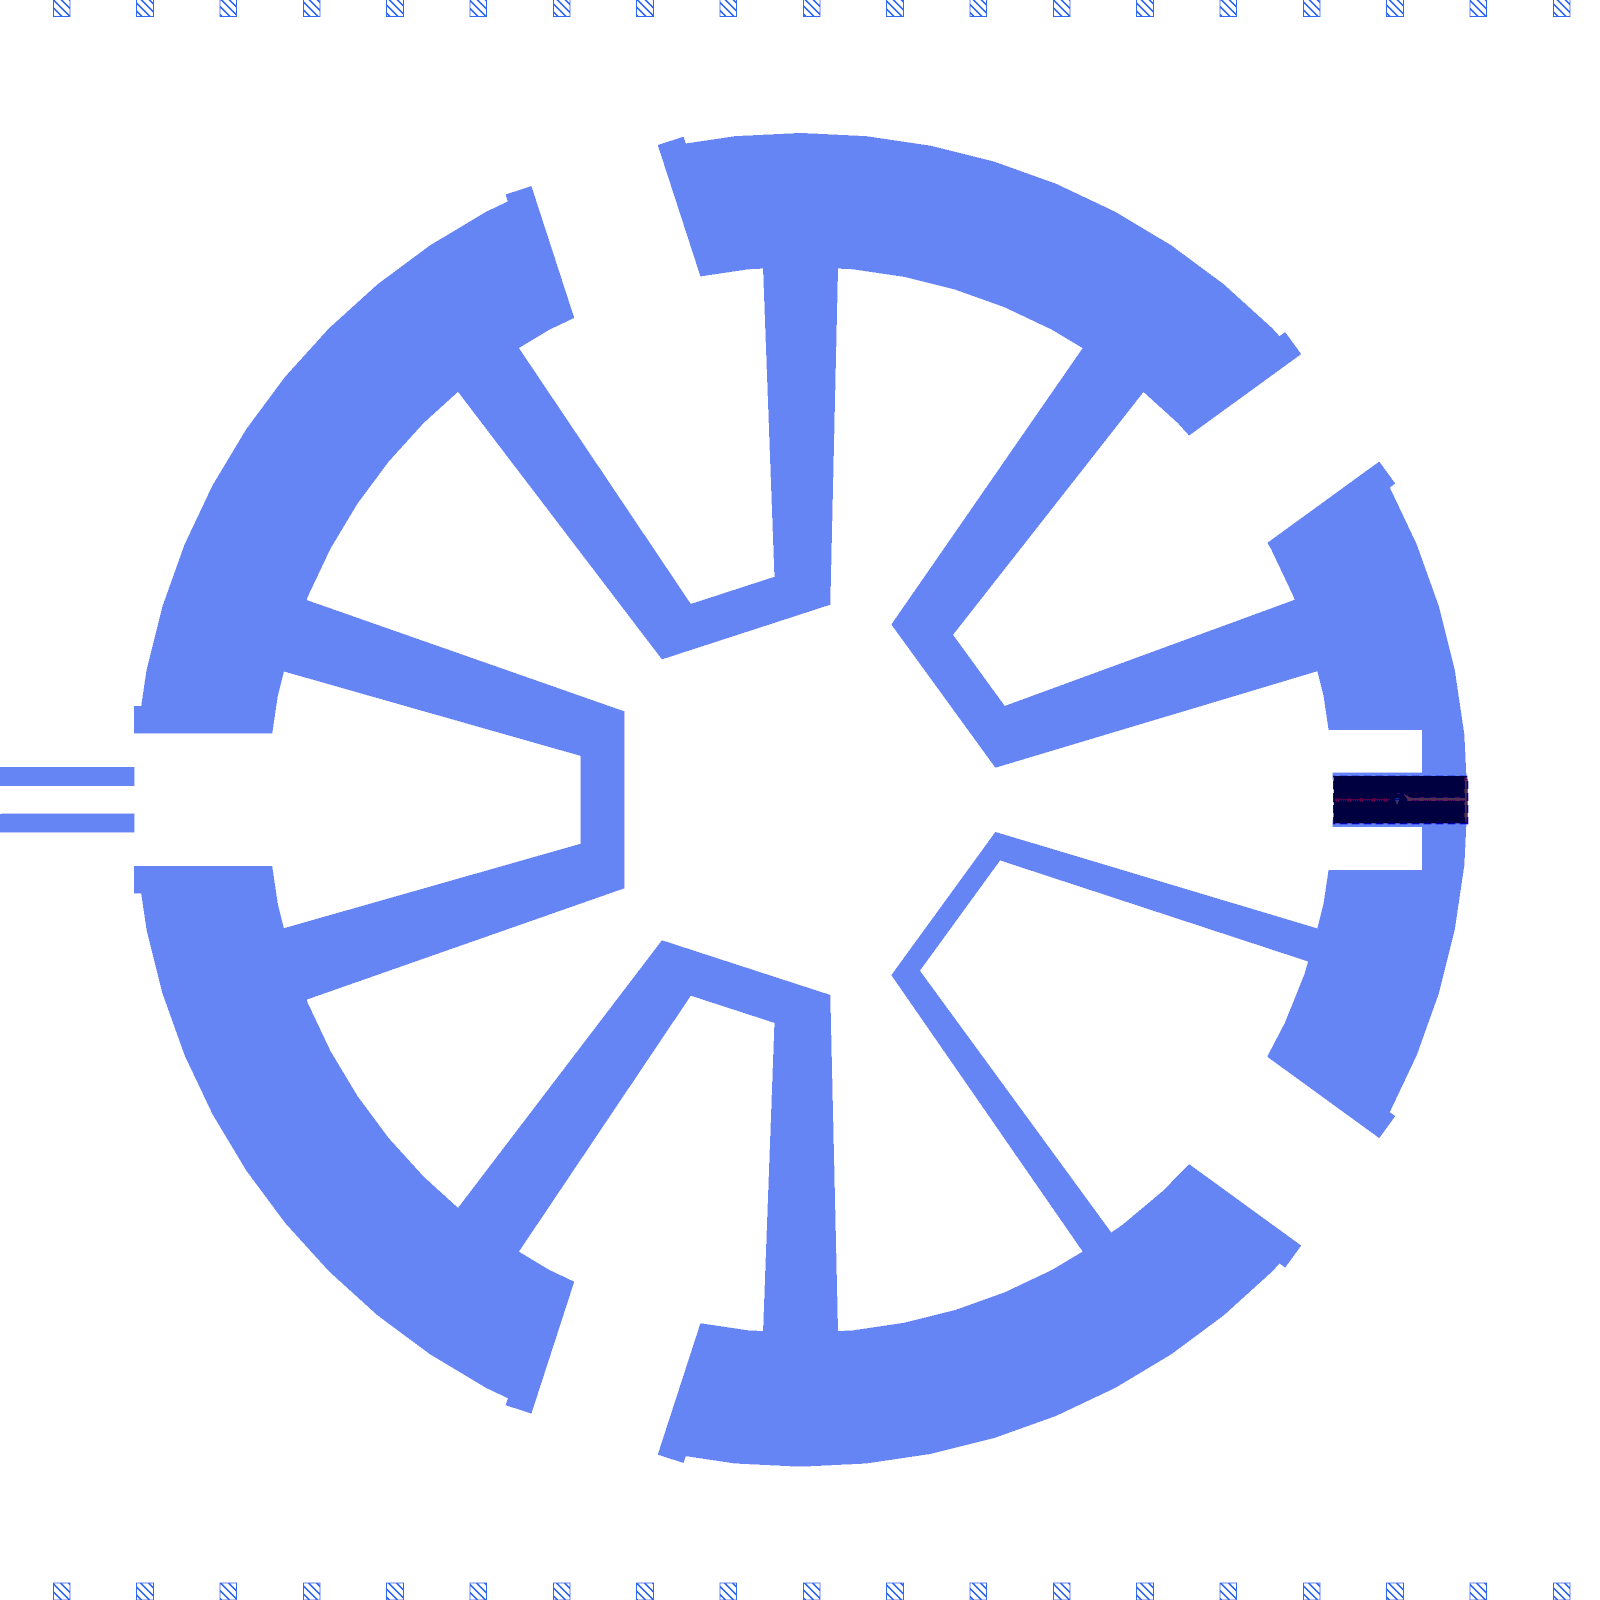

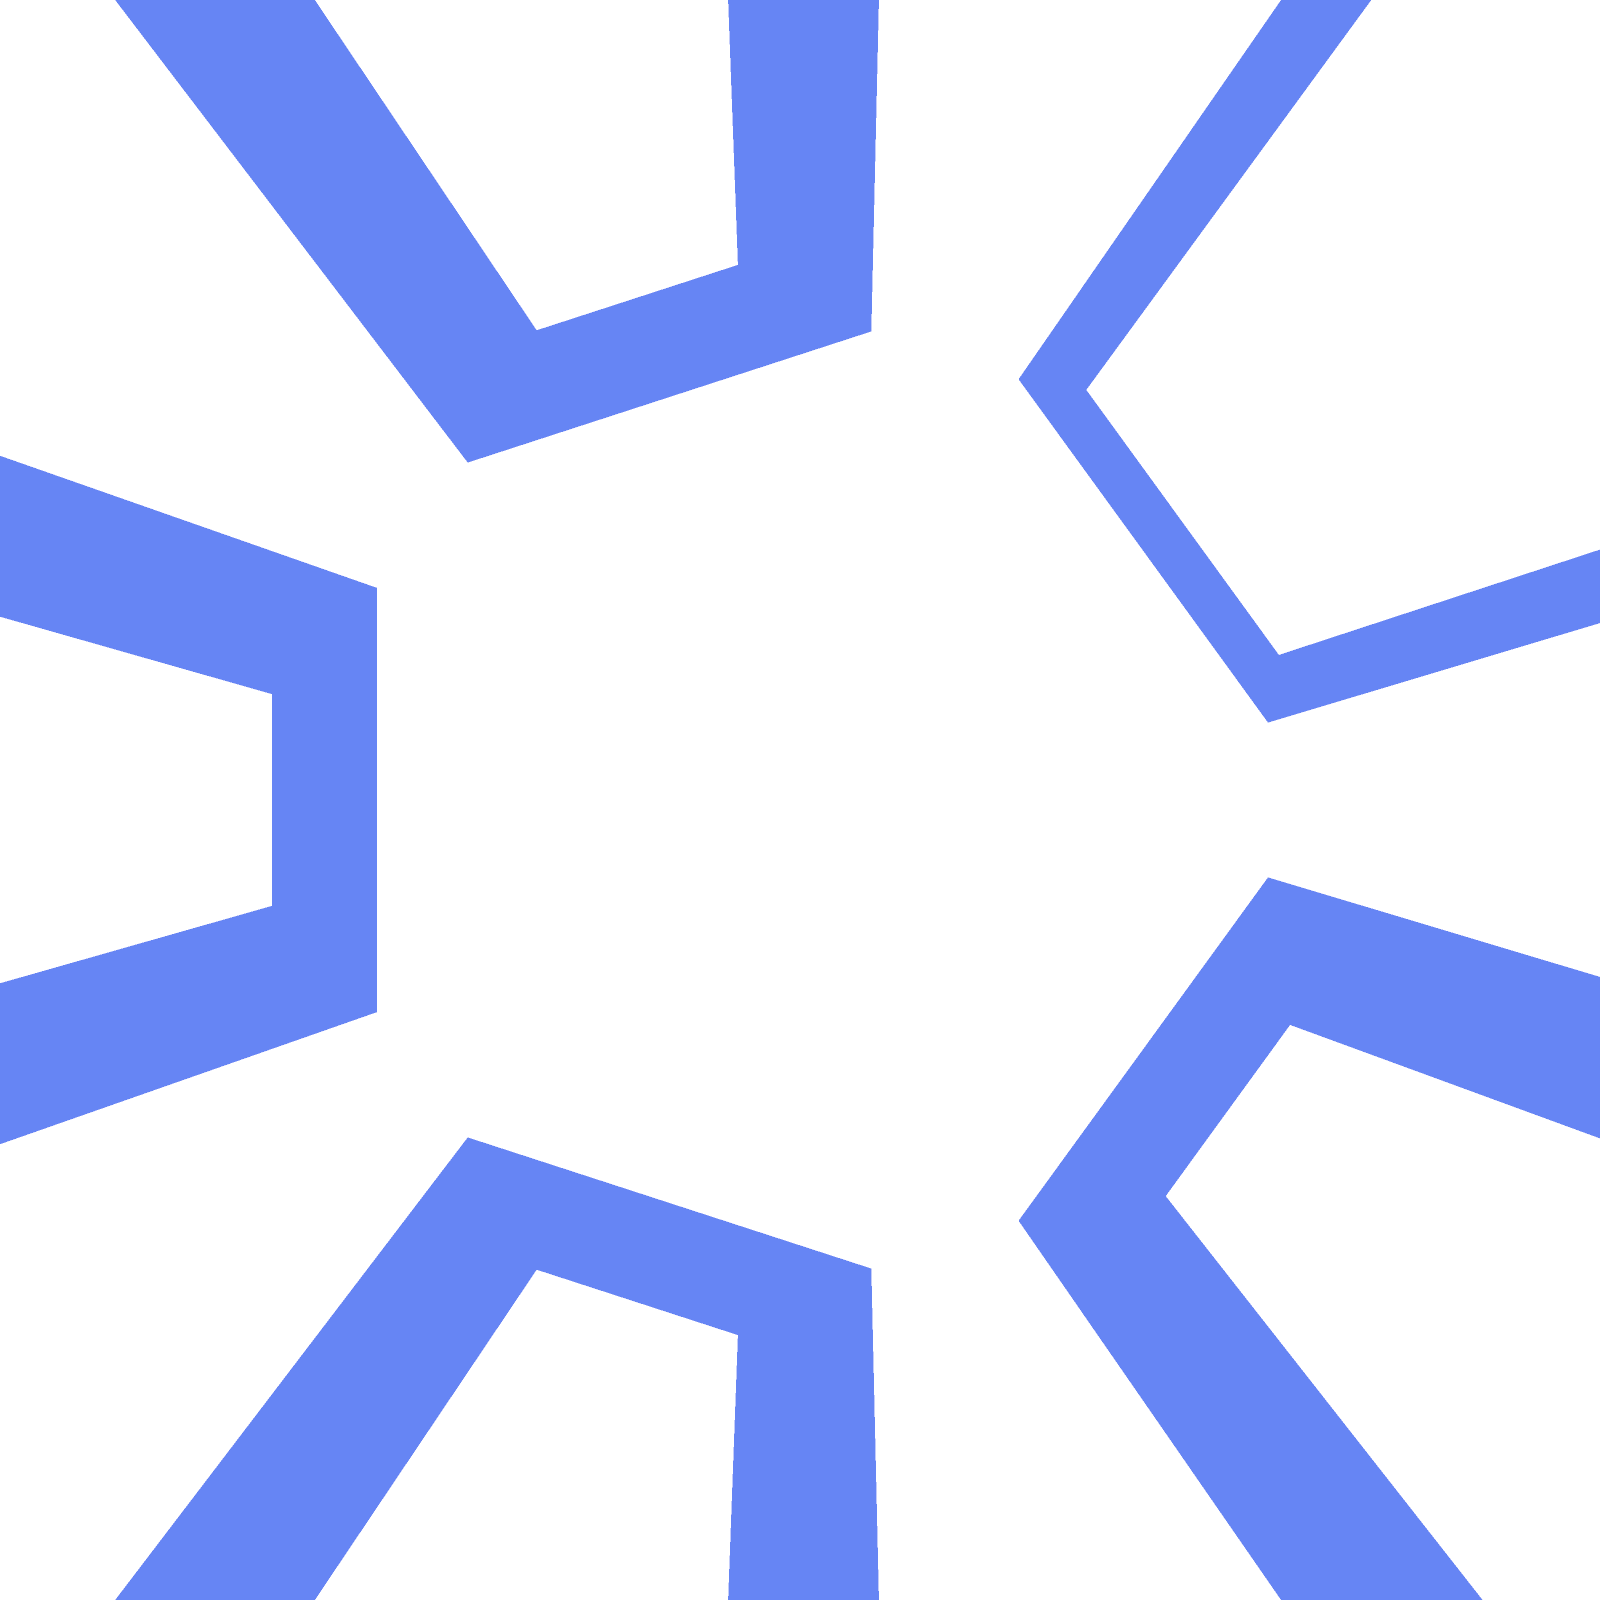

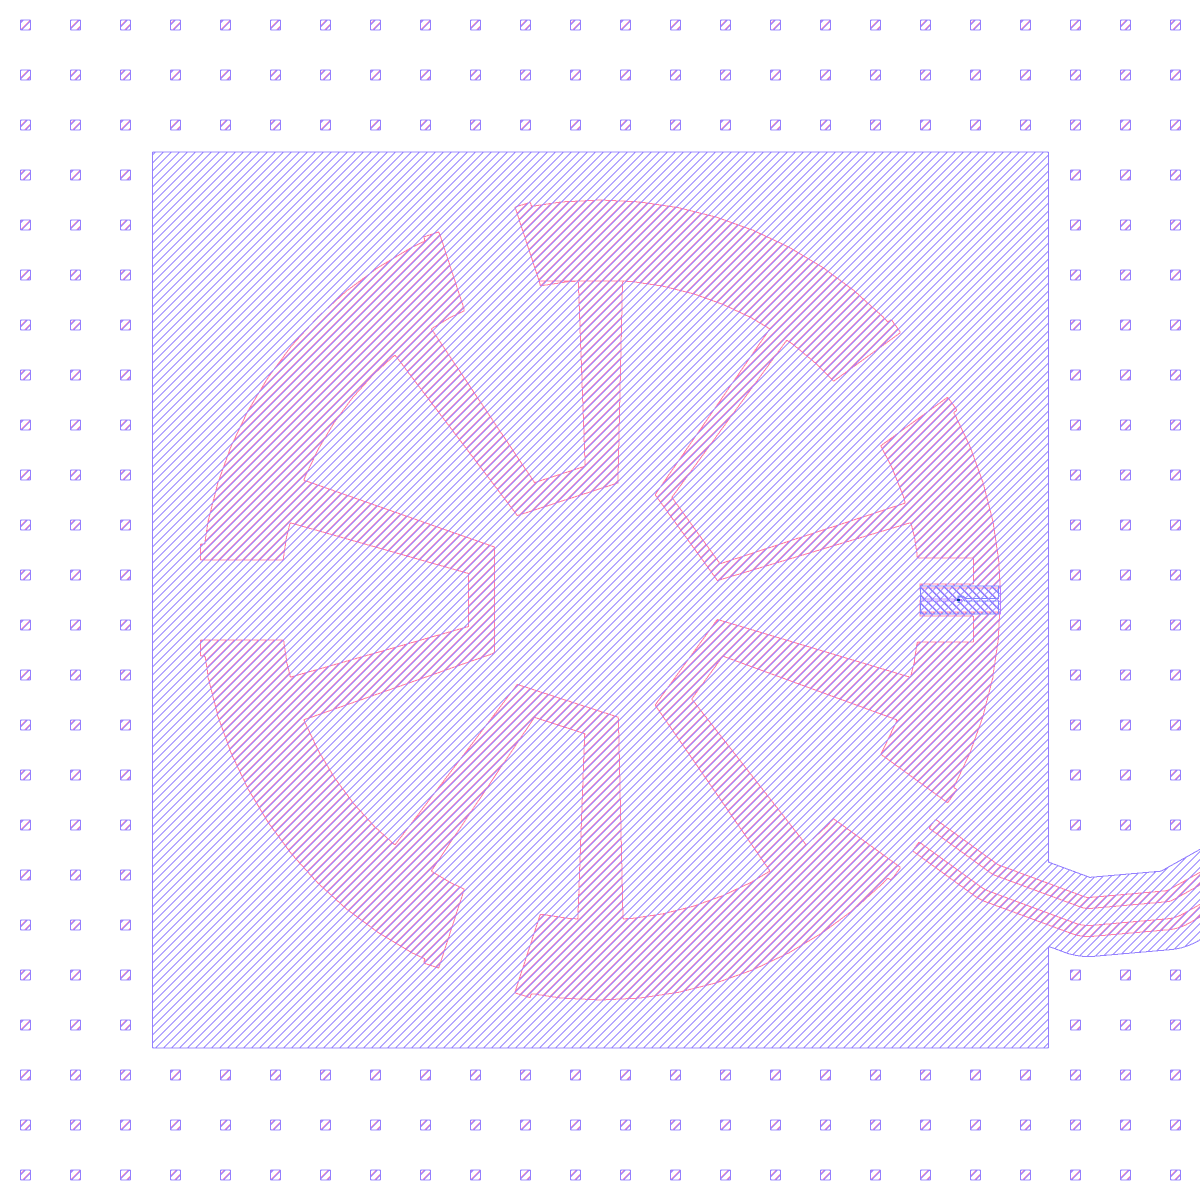

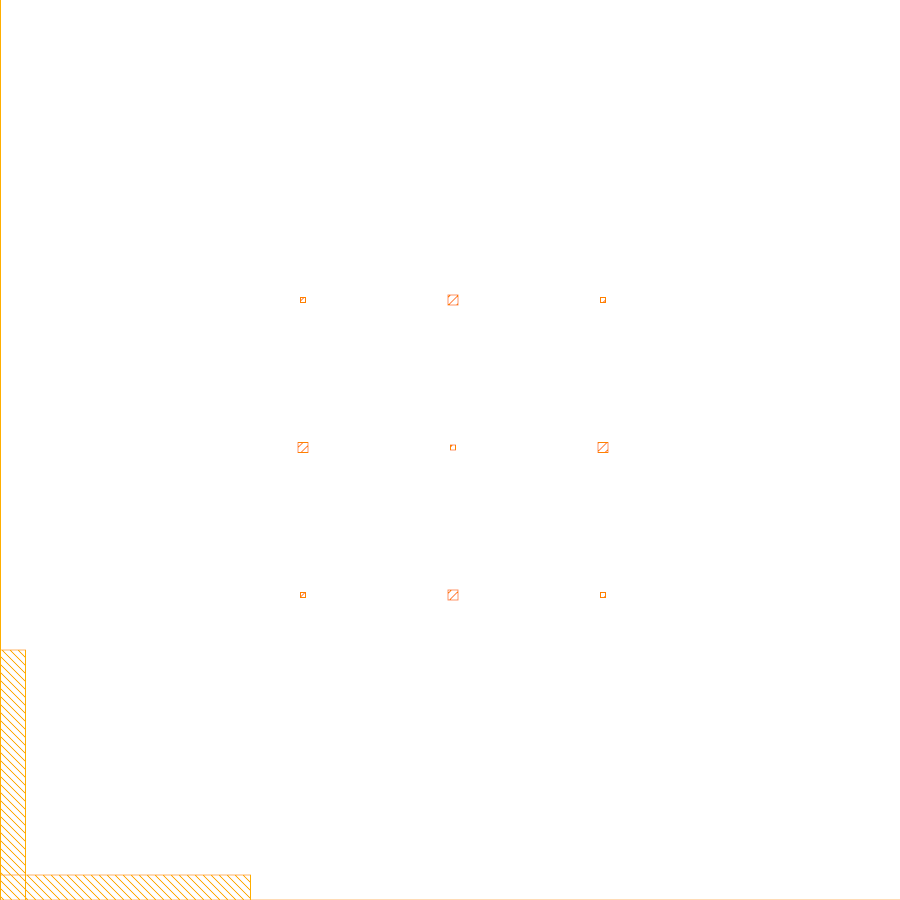

In [16]:
dx, dy = d.data["instances"]["D5"]["place"]["at"]
zx, zy = d.data["instances"]["Z3"]["place"]["at"]
show_snapshot(d, OUT / "m54_wallraff_cell.png", size=(1400, 1400))
show_snapshot(d, OUT / "m54_wallraff_cell_cell.png", box=(dx - 350, dy - 350, zx + 350, zy + 350), size=(1600, 485))
show_snapshot(d, OUT / "m54_wallraff_cell_d5.png", box=(dx - 240, dy - 240, dx + 240, dy + 240), width=420)
show_snapshot(d, OUT / "m54_wallraff_cell_z3.png", box=(zx - 240, zy - 240, zx + 240, zy + 240), width=420)
show_snapshot(d, OUT / "m54_wallraff_cell_jj.png", box=(dx - 100, dy - 100, dx + 100, dy + 100), width=300)
snap_file(Path("build") / "m54_wallraff_cell_fab.oas", OUT / "m54_wallraff_cell_cheese.png",
          box=(dx - 300, dy - 300, dx + 300, dy + 300), size=(1200, 1200), width=420)
show_snapshot(d, OUT / "m54_wallraff_cell_frame.png", box=(-2595.4, -3400, -1695.4, -2500), size=(900, 900), width=300);

## 16 · Summary

| | |
|---|---|
| matches the source | both StarQubits with the builder's options and pad rotations, their positions, the traced coupler line (31 points, 8.5 / 5.5 µm, fillet 15 µm), the cut-out's extent and the margin-0 sim box |
| PDK changes | the 7.5 mm Quantcore die with the QCT frame round the cut-out; sapphire stack; trilayer junctions (PDK nominal); PDK cheese band; content centred (no shift needed); no pads to place |
| differs | junctions where the source has none; the free pads are grounded through `ShortToGround`s, not merged into the ground metal |
| LOM (this run) | LOM estimates: C_Σ 104 fF (Elmer 167 fF), C(island, coupler) 15.0 fF (Elmer 18.4 fF); D5 / Z3 6.40 / 6.72 GHz dressed (QuCat 6.64 / 6.97, fully mixed through the too-light coupler node); from the source's Elmer C-matrix 4.54 / 4.56 GHz, mixed 76 / 24 %; iterate (D5 `center_radius` 53 → 70 µm): D5 −413 MHz, Z3 −125 MHz |
| PDK design warnings | none |
| open | the LOM StarQubit / coupler-line models (lom requests); the FEM job is exported, not solved (`RUN_FEM = False`) |